

# Predictive Analysis - Heart Failure Retrospective Study Analysis




### Import libraries

These libraries are used for:

- `pandas` and `numpy` – data preparation
- `matplotlib` and `seaborn` – visualization
- `scikit-learn` – predictive modeling and evaluation

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split,StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    classification_report, roc_auc_score
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


# QUESTION 1

## Can the combination of echocardiographic measurements distinguish patients with different types of heart failure?

### Explanation

The objective is to determine whether echocardiographic measurements contain enough information to distinguish different heart-failure types.

### Target variable

`type_of_heart_failure`

### Predictor variables

- `lvef`
- `left_ventricular_end_diastolic_diameter_lv`
- `mitral_valve_ems`
- `mitral_valve_ams`
- `ea`
- `tricuspid_valve_return_velocity`
- `tricuspid_valve_return_pressure`

# Load the cleaned heart-failure dataset

In [81]:
#file_path = Path(r"10_PyMasters_Cleaned_Heartdata(1).csv")
datasetPath = Path("cardiac_failure")
heart_df = pd.read_csv(datasetPath /'10_PyMasters_Cleaned_Heartdata.csv')

print("Dataset loaded successfully!")
print("Rows:", heart_df.shape[0])
print("Columns:", heart_df.shape[1])

Dataset loaded successfully!
Rows: 2008
Columns: 158


### Cell 3 – Select the variables needed for Q1

In [82]:
q1_features = [
    "lvef",
    "left_ventricular_end_diastolic_diameter_lv",
    "mitral_valve_ems",
    "mitral_valve_ams",
    "ea",
    "tricuspid_valve_return_velocity",
    "tricuspid_valve_return_pressure"
]

q1_target = "type_of_heart_failure"

q1_df = heart_df[q1_features + [q1_target]].copy()

print("Q1 dataset shape:", q1_df.shape)
q1_df.head()

Q1 dataset shape: (2008, 8)


,lvef,left_ventricular_end_diastolic_diameter_lv,mitral_valve_ems,mitral_valve_ams,ea,tricuspid_valve_return_velocity,tricuspid_valve_return_pressure,type_of_heart_failure
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Both
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Both
2,NaN,40.0,1.16,1.52,NaN,3.34,47.0,Both
3,NaN,46.0,0.84,0.12,7.0,2.80,32.0,Both
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Both


### Cell 4 – Check missing values

In [83]:
q1_df.isnull().sum()

lvef                                          1373
left_ventricular_end_diastolic_diameter_lv     697
mitral_valve_ems                              1028
mitral_valve_ams                              1458
ea                                            1615
tricuspid_valve_return_velocity               1218
tricuspid_valve_return_pressure               1826
type_of_heart_failure                            0
dtype: int64

### Cell 5 – Check the target categories

In [84]:
print(q1_df[q1_target].value_counts())

type_of_heart_failure
Both     1480
Left      477
Right      51
Name: count, dtype: int64


### Cell 6 – Visualization: Distribution of heart-failure types

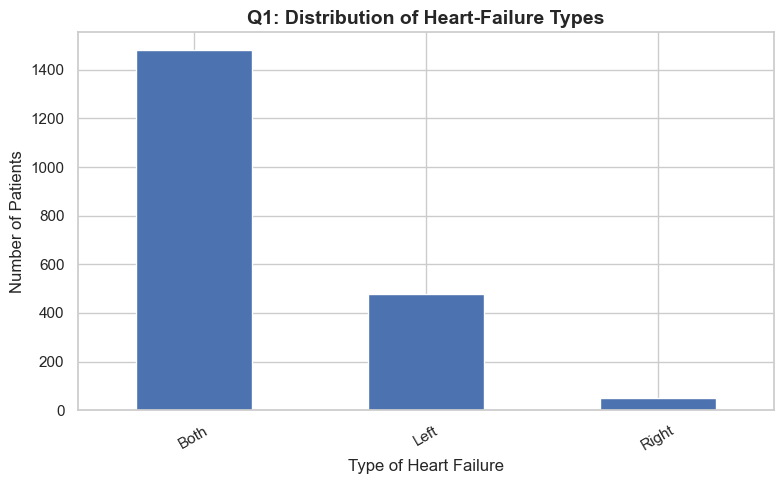

In [85]:
plt.figure(figsize=(8, 5))

q1_df[q1_target].value_counts().plot(kind="bar")

plt.title(
    "Q1: Distribution of Heart-Failure Types",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Type of Heart Failure")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Cell 7 – Prepare predictors (X) and target (y)

In [86]:
q1_df = q1_df.dropna(subset=[q1_target])

X_q1 = q1_df[q1_features]
y_q1 = q1_df[q1_target].astype(str).str.strip()

print("X shape:", X_q1.shape)
print("y shape:", y_q1.shape)

X shape: (2008, 7)
y shape: (2008,)


### Cell 8 – Split into training and testing data

In [87]:
X_train_q1, X_test_q1, y_train_q1, y_test_q1 = train_test_split(
    X_q1,
    y_q1,
    test_size=0.20,
    random_state=42,
    stratify=y_q1
)

print("Training records:", len(X_train_q1))
print("Testing records:", len(X_test_q1))

Training records: 1606
Testing records: 402


### Cell 9 – Build Logistic Regression model

In [88]:
q1_logistic = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

q1_logistic.fit(X_train_q1, y_train_q1)

q1_logistic_pred = q1_logistic.predict(X_test_q1)

print("Logistic Regression prediction completed!")

Logistic Regression prediction completed!


### Cell 10 – Build Decision Tree model

In [89]:
q1_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

q1_tree.fit(X_train_q1, y_train_q1)

q1_tree_pred = q1_tree.predict(X_test_q1)

print("Decision Tree prediction completed!")

Decision Tree prediction completed!


### Cell 11 – Build Random Forest model

In [90]:
q1_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ))
])

q1_rf.fit(X_train_q1, y_train_q1)

q1_rf_pred = q1_rf.predict(X_test_q1)

print("Random Forest prediction completed!")

Random Forest prediction completed!


### Cell 12 – Compare model performance

In [91]:
q1_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test_q1, q1_logistic_pred),
        accuracy_score(y_test_q1, q1_tree_pred),
        accuracy_score(y_test_q1, q1_rf_pred)
    ],
    "Precision": [
        precision_score(y_test_q1, q1_logistic_pred, average="weighted", zero_division=0),
        precision_score(y_test_q1, q1_tree_pred, average="weighted", zero_division=0),
        precision_score(y_test_q1, q1_rf_pred, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_q1, q1_logistic_pred, average="weighted", zero_division=0),
        recall_score(y_test_q1, q1_tree_pred, average="weighted", zero_division=0),
        recall_score(y_test_q1, q1_rf_pred, average="weighted", zero_division=0)
    ],
    "F1": [
        f1_score(y_test_q1, q1_logistic_pred, average="weighted", zero_division=0),
        f1_score(y_test_q1, q1_tree_pred, average="weighted", zero_division=0),
        f1_score(y_test_q1, q1_rf_pred, average="weighted", zero_division=0)
    ]
})

q1_results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.196517,0.676191,0.196517,0.156857
1,Decision Tree,0.263682,0.615284,0.263682,0.201329
2,Random Forest,0.684080,0.664169,0.684080,0.672988


### Cell 13 – Visualization: Model performance

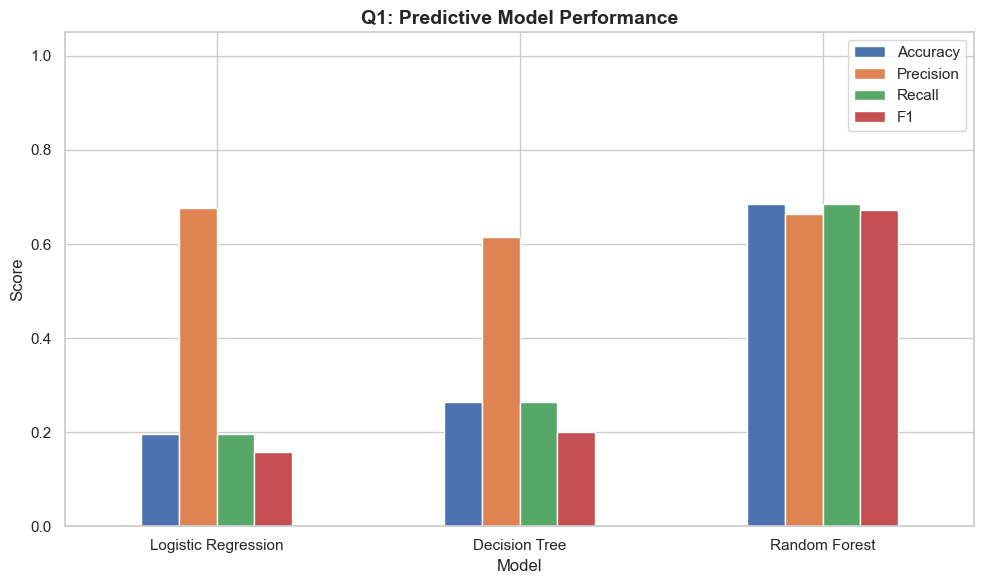

In [92]:
q1_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Q1: Predictive Model Performance",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Cell 14 – Visualization: Random Forest confusion matrix

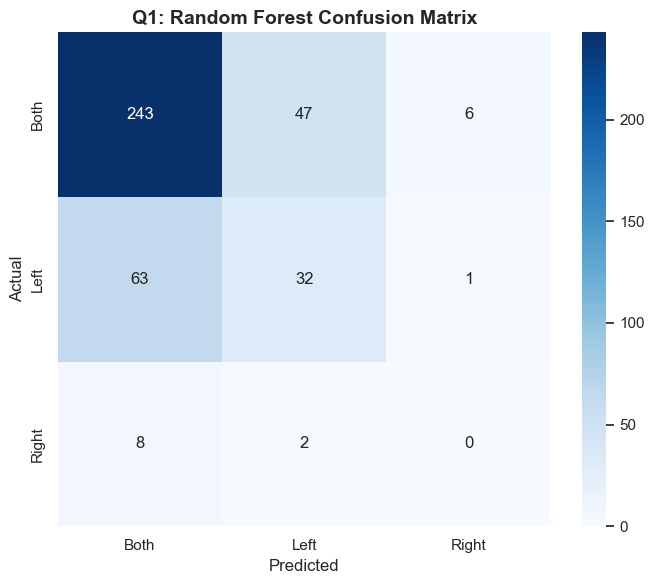

In [93]:
q1_cm = confusion_matrix(y_test_q1, q1_rf_pred)

plt.figure(figsize=(7, 6))

sns.heatmap(
    q1_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y_test_q1.unique()),
    yticklabels=sorted(y_test_q1.unique())
)

plt.title(
    "Q1: Random Forest Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### Cell 15 – Visualization: Echocardiographic feature importance

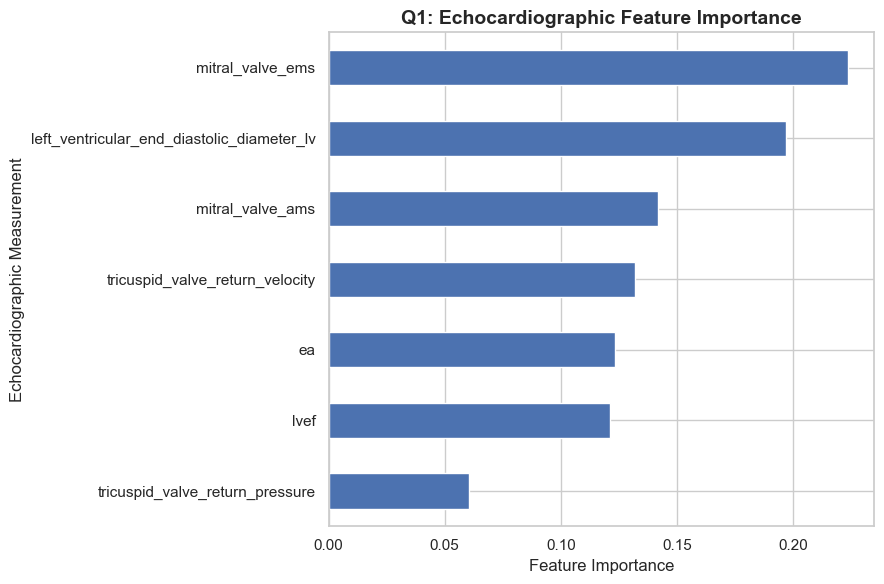

In [94]:
q1_importance = pd.Series(
    q1_rf.named_steps["model"].feature_importances_,
    index=q1_features
).sort_values(ascending=True)

plt.figure(figsize=(9, 6))

q1_importance.plot(kind="barh")

plt.title(
    "Q1: Echocardiographic Feature Importance",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Feature Importance")
plt.ylabel("Echocardiographic Measurement")

plt.tight_layout()
plt.show()

### Q1 – Assignment interpretation

Use the actual values produced above.

**Suggested format for your report:**

> The analysis evaluated whether echocardiographic measurements could distinguish different types of heart failure. Logistic Regression, Decision Tree, and Random Forest models were trained using the selected echocardiographic variables. Model performance was evaluated using Accuracy, Precision, Recall, and F1-score. The confusion matrix shows the correctly and incorrectly classified heart-failure categories. Random Forest feature importance identifies which echocardiographic measurements contributed most to the predictions.

Do not write a specific numerical result until the notebook has been run.

# QUESTION 2

## Can mitral-valve measurements predict the presence of combined (Both) heart failure?

### Explanation

This question focuses specifically on mitral-valve measurements and asks whether they can distinguish patients classified as `Both` from patients in other heart-failure categories.

### Target

`Both` = 1  
`Other` = 0

### Predictors

- `mitral_valve_ems`
- `mitral_valve_ams`
- `ea`

### Cell 1 – Create the Q2 dataset

In [95]:
q2_features = [
    "mitral_valve_ems",
    "mitral_valve_ams",
    "ea"
]

q2_df = heart_df[
    q2_features + ["type_of_heart_failure"]
].copy()

q2_df.head()

,mitral_valve_ems,mitral_valve_ams,ea,type_of_heart_failure
0,NaN,NaN,NaN,Both
1,NaN,NaN,NaN,Both
2,1.16,1.52,NaN,Both
3,0.84,0.12,7.0,Both
4,NaN,NaN,NaN,Both


### Cell 2 – Create the binary prediction target

In [96]:
q2_df["combined_heart_failure"] = np.where(
    q2_df["type_of_heart_failure"].astype(str).str.strip().eq("Both"),
    1,
    np.where(
        q2_df["type_of_heart_failure"].notna(),
        0,
        np.nan
    )
)

q2_df["combined_heart_failure"].value_counts(dropna=False)

combined_heart_failure
1.0    1480
0.0     528
Name: count, dtype: int64

### Cell 3 – Check missing values

In [97]:
q2_df[q2_features + ["combined_heart_failure"]].isnull().sum()

mitral_valve_ems          1028
mitral_valve_ams          1458
ea                        1615
combined_heart_failure       0
dtype: int64

### Cell 4 – Visualization: Combined heart-failure distribution

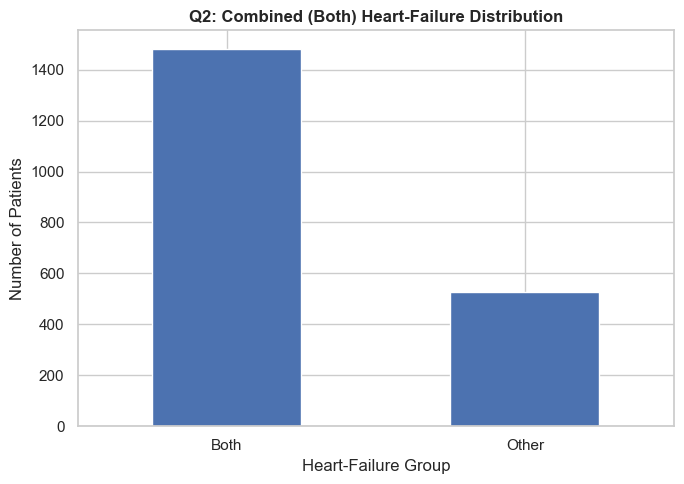

In [98]:
q2_plot = q2_df["combined_heart_failure"].map({
    0: "Other",
    1: "Both"
})

q2_plot.value_counts().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title(
    "Q2: Combined (Both) Heart-Failure Distribution",
    fontweight="bold"
)
plt.xlabel("Heart-Failure Group")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Cell 5 – Visualization: Mitral measurements

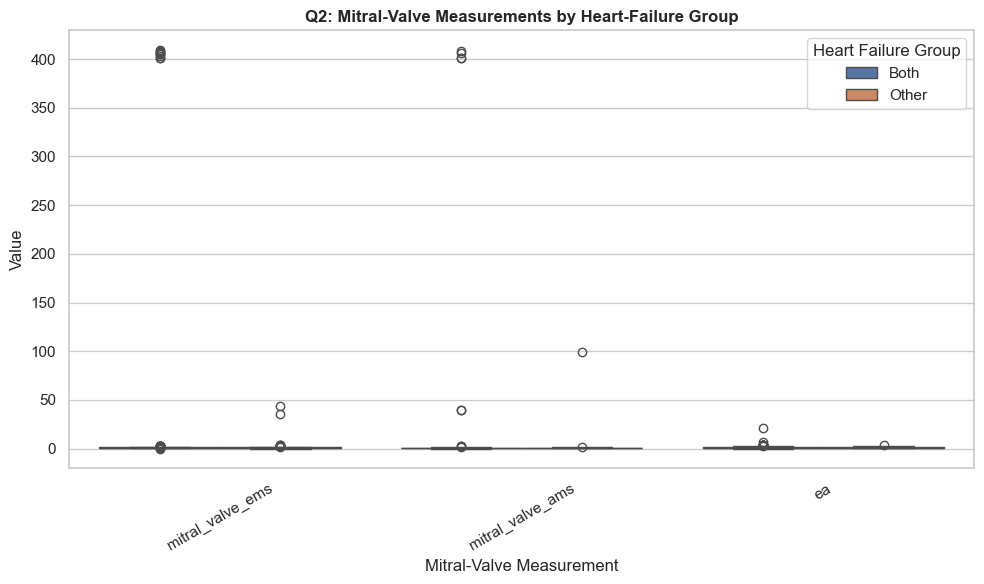

In [99]:
q2_box = q2_df.dropna(
    subset=["combined_heart_failure"]
).copy()

q2_box["Heart Failure Group"] = q2_box[
    "combined_heart_failure"
].map({
    0: "Other",
    1: "Both"
})

q2_long = q2_box.melt(
    id_vars="Heart Failure Group",
    value_vars=q2_features,
    var_name="Measurement",
    value_name="Value"
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=q2_long,
    x="Measurement",
    y="Value",
    hue="Heart Failure Group"
)

plt.title(
    "Q2: Mitral-Valve Measurements by Heart-Failure Group",
    fontweight="bold"
)
plt.xlabel("Mitral-Valve Measurement")
plt.ylabel("Value")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Cell 6 – Prepare X and y

In [100]:
q2_df = q2_df.dropna(
    subset=["combined_heart_failure"]
)

X_q2 = q2_df[q2_features]
y_q2 = q2_df["combined_heart_failure"].astype(int)

print("X shape:", X_q2.shape)
print("y shape:", y_q2.shape)

X shape: (2008, 3)
y shape: (2008,)


### Cell 7 – Train/test split

In [101]:
X_train_q2, X_test_q2, y_train_q2, y_test_q2 = train_test_split(
    X_q2,
    y_q2,
    test_size=0.20,
    random_state=42,
    stratify=y_q2
)

print("Training records:", len(X_train_q2))
print("Testing records:", len(X_test_q2))

Training records: 1606
Testing records: 402


### Cell 8 – Logistic Regression

In [102]:
q2_logistic = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

q2_logistic.fit(X_train_q2, y_train_q2)
q2_logistic_pred = q2_logistic.predict(X_test_q2)

print("Q2 Logistic Regression completed!")

Q2 Logistic Regression completed!


### Cell 9 – Decision Tree

In [103]:
q2_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

q2_tree.fit(X_train_q2, y_train_q2)
q2_tree_pred = q2_tree.predict(X_test_q2)

print("Q2 Decision Tree completed!")

Q2 Decision Tree completed!


### Cell 10 – Random Forest

In [104]:
q2_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ))
])

q2_rf.fit(X_train_q2, y_train_q2)
q2_rf_pred = q2_rf.predict(X_test_q2)

print("Q2 Random Forest completed!")

Q2 Random Forest completed!


### Cell 11 – Evaluation

In [105]:
q2_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test_q2, q2_logistic_pred),
        accuracy_score(y_test_q2, q2_tree_pred),
        accuracy_score(y_test_q2, q2_rf_pred)
    ],
    "Precision": [
        precision_score(y_test_q2, q2_logistic_pred, zero_division=0),
        precision_score(y_test_q2, q2_tree_pred, zero_division=0),
        precision_score(y_test_q2, q2_rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_q2, q2_logistic_pred, zero_division=0),
        recall_score(y_test_q2, q2_tree_pred, zero_division=0),
        recall_score(y_test_q2, q2_rf_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test_q2, q2_logistic_pred, zero_division=0),
        f1_score(y_test_q2, q2_tree_pred, zero_division=0),
        f1_score(y_test_q2, q2_rf_pred, zero_division=0)
    ]
})

q2_results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.310945,0.743590,0.097973,0.173134
1,Decision Tree,0.661692,0.758065,0.793919,0.775578
2,Random Forest,0.684080,0.752239,0.851351,0.798732


### Cell 12 – Visualization: Model performance

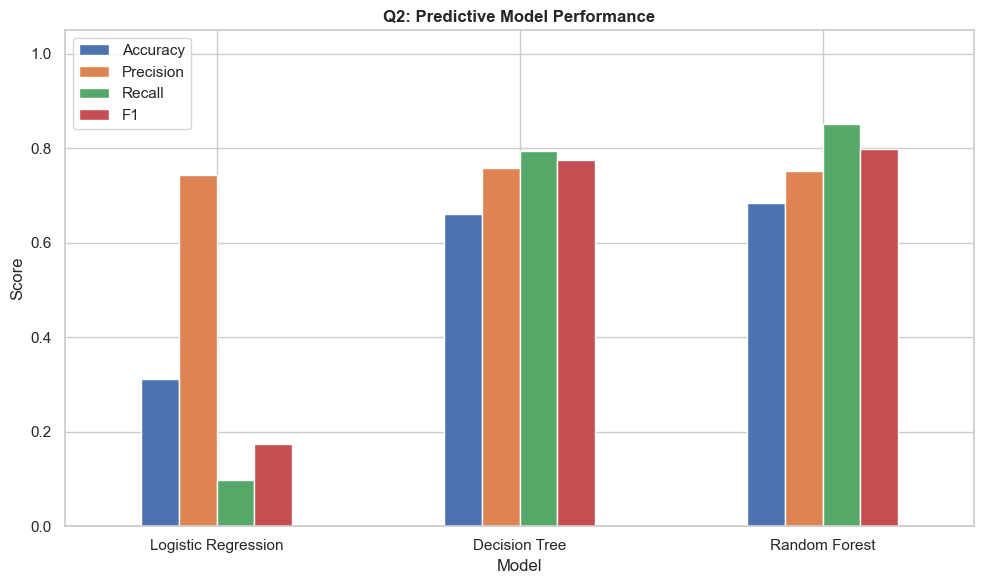

In [106]:
q2_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Q2: Predictive Model Performance",
    fontweight="bold"
)
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Cell 13 – Visualization: Confusion matrix

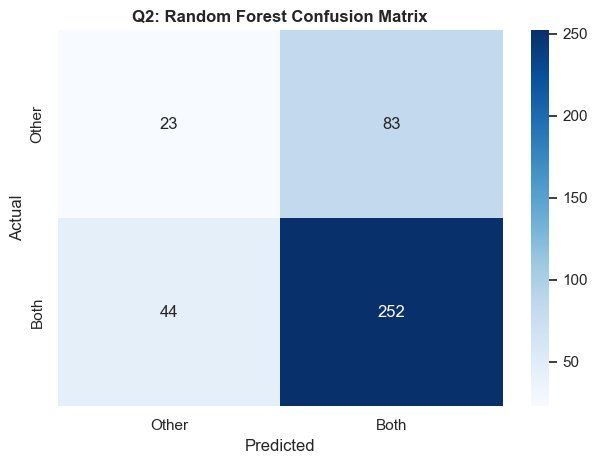

In [107]:
q2_cm = confusion_matrix(y_test_q2, q2_rf_pred)

sns.heatmap(
    q2_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Other", "Both"],
    yticklabels=["Other", "Both"]
)

plt.title(
    "Q2: Random Forest Confusion Matrix",
    fontweight="bold"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### Cell 14 – Visualization: Feature importance

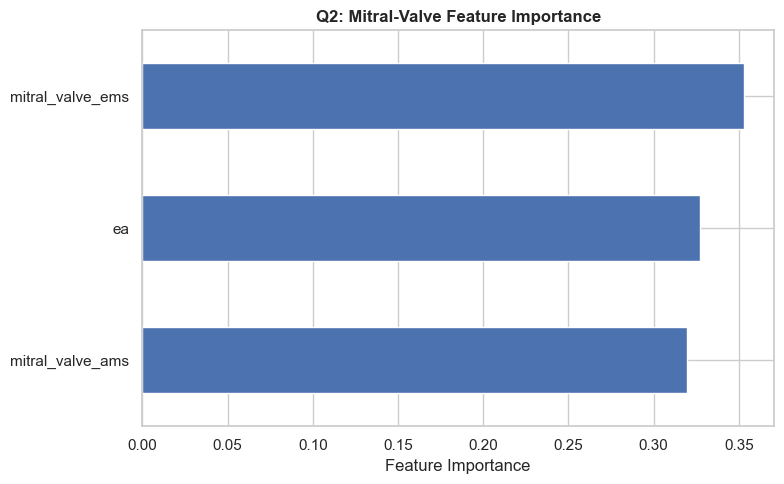

In [108]:
q2_importance = pd.Series(
    q2_rf.named_steps["model"].feature_importances_,
    index=q2_features
).sort_values(ascending=True)

q2_importance.plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title(
    "Q2: Mitral-Valve Feature Importance",
    fontweight="bold"
)
plt.xlabel("Feature Importance")

plt.tight_layout()
plt.show()

### Q2 – Assignment interpretation

> The analysis evaluated whether mitral-valve measurements could distinguish patients with combined (Both) heart failure from other heart-failure categories. The predictive models were evaluated using Accuracy, Precision, Recall, and F1-score. The box plot shows the distribution of mitral-valve measurements across the two groups, while the feature-importance chart identifies the measurements that contributed most to the Random Forest predictions.

# QUESTION 3

## Can tricuspid-valve measurements distinguish Right-sided heart failure from other heart-failure types?

### Explanation

This question focuses on two tricuspid-valve measurements and evaluates whether they can distinguish the `Right` heart-failure category from other categories.

### Predictors

- `tricuspid_valve_return_velocity`
- `tricuspid_valve_return_pressure`

### Target

`Right` = 1  
`Other` = 0

### Cell 1 – Create Q3 dataset and target

In [109]:
q3_features = [
    "tricuspid_valve_return_velocity",
    "tricuspid_valve_return_pressure"
]

q3_df = heart_df[
    q3_features + ["type_of_heart_failure"]
].copy()

q3_df["right_sided_heart_failure"] = np.where(
    q3_df["type_of_heart_failure"].astype(str).str.strip().eq("Right"),
    1,
    np.where(
        q3_df["type_of_heart_failure"].notna(),
        0,
        np.nan
    )
)

q3_df.head()

,tricuspid_valve_return_velocity,tricuspid_valve_return_pressure,type_of_heart_failure,right_sided_heart_failure
0,NaN,NaN,Both,0.0
1,NaN,NaN,Both,0.0
2,3.34,47.0,Both,0.0
3,2.80,32.0,Both,0.0
4,NaN,NaN,Both,0.0


### Cell 2 – Check target distribution

In [110]:
q3_df["right_sided_heart_failure"].value_counts(dropna=False)

right_sided_heart_failure
0.0    1957
1.0      51
Name: count, dtype: int64

### Cell 3 – Visualization: Tricuspid measurements

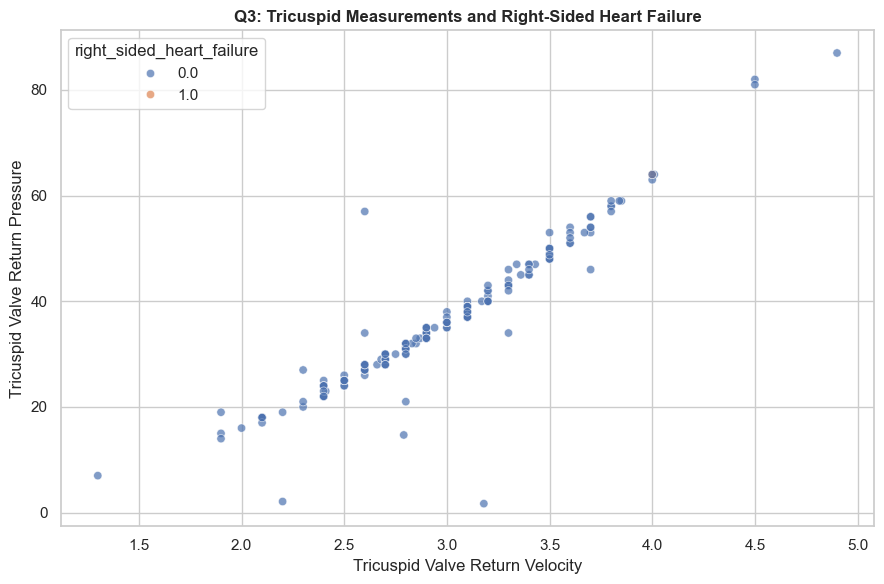

In [111]:
q3_plot = q3_df.dropna(
    subset=["right_sided_heart_failure"]
).copy()

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=q3_plot,
    x="tricuspid_valve_return_velocity",
    y="tricuspid_valve_return_pressure",
    hue="right_sided_heart_failure",
    alpha=0.7
)

plt.title(
    "Q3: Tricuspid Measurements and Right-Sided Heart Failure",
    fontweight="bold"
)
plt.xlabel("Tricuspid Valve Return Velocity")
plt.ylabel("Tricuspid Valve Return Pressure")

plt.tight_layout()
plt.show()

### Cell 4 – Prepare X and y

In [112]:
q3_df = q3_df.dropna(
    subset=["right_sided_heart_failure"]
)

X_q3 = q3_df[q3_features]
y_q3 = q3_df["right_sided_heart_failure"].astype(int)

print("X shape:", X_q3.shape)
print("y shape:", y_q3.shape)

X shape: (2008, 2)
y shape: (2008,)


### Cell 5 – Train/test split

In [113]:
X_train_q3, X_test_q3, y_train_q3, y_test_q3 = train_test_split(
    X_q3,
    y_q3,
    test_size=0.20,
    random_state=42,
    stratify=y_q3
)

print("Training records:", len(X_train_q3))
print("Testing records:", len(X_test_q3))

Training records: 1606
Testing records: 402


### Cell 6 – Logistic Regression

In [114]:
q3_logistic = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

q3_logistic.fit(X_train_q3, y_train_q3)
q3_logistic_pred = q3_logistic.predict(X_test_q3)

print("Q3 Logistic Regression completed!")

Q3 Logistic Regression completed!


### Cell 7 – Decision Tree

In [115]:
q3_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

q3_tree.fit(X_train_q3, y_train_q3)
q3_tree_pred = q3_tree.predict(X_test_q3)

print("Q3 Decision Tree completed!")

Q3 Decision Tree completed!


### Cell 8 – Random Forest

In [116]:
q3_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ))
])

q3_rf.fit(X_train_q3, y_train_q3)
q3_rf_pred = q3_rf.predict(X_test_q3)

print("Q3 Random Forest completed!")

Q3 Random Forest completed!


### Cell 9 – Evaluation

In [117]:
q3_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test_q3, q3_logistic_pred),
        accuracy_score(y_test_q3, q3_tree_pred),
        accuracy_score(y_test_q3, q3_rf_pred)
    ],
    "Precision": [
        precision_score(y_test_q3, q3_logistic_pred, zero_division=0),
        precision_score(y_test_q3, q3_tree_pred, zero_division=0),
        precision_score(y_test_q3, q3_rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_q3, q3_logistic_pred, zero_division=0),
        recall_score(y_test_q3, q3_tree_pred, zero_division=0),
        recall_score(y_test_q3, q3_rf_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test_q3, q3_logistic_pred, zero_division=0),
        f1_score(y_test_q3, q3_tree_pred, zero_division=0),
        f1_score(y_test_q3, q3_rf_pred, zero_division=0)
    ]
})

q3_results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.800995,0.013889,0.1,0.024390
1,Decision Tree,0.216418,0.018927,0.6,0.036697
2,Random Forest,0.305970,0.021352,0.6,0.041237


### Cell 10 – Visualization: Model comparison

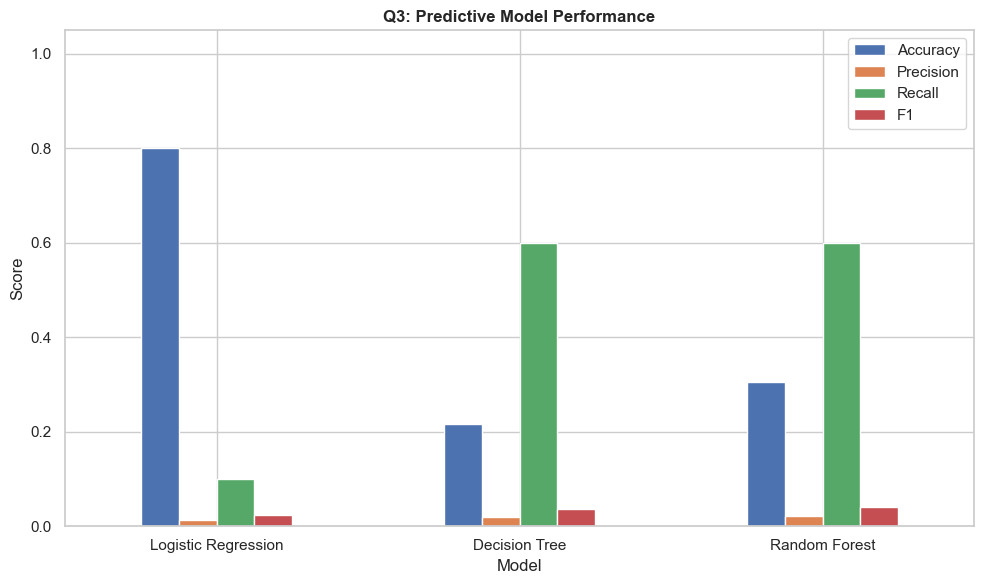

In [118]:
q3_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Q3: Predictive Model Performance",
    fontweight="bold"
)
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Cell 11 – Visualization: Confusion matrix

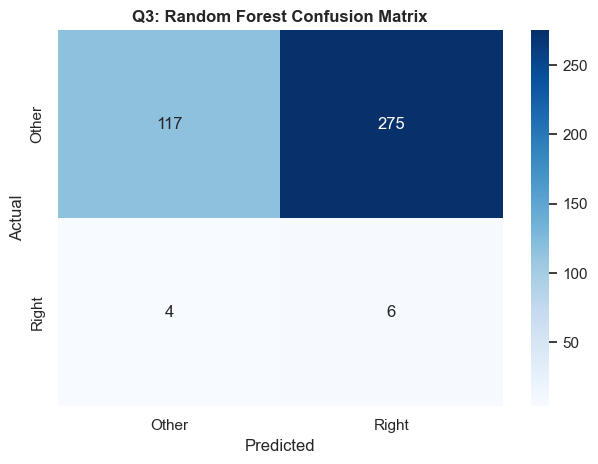

In [119]:
q3_cm = confusion_matrix(y_test_q3, q3_rf_pred)

sns.heatmap(
    q3_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Other", "Right"],
    yticklabels=["Other", "Right"]
)

plt.title(
    "Q3: Random Forest Confusion Matrix",
    fontweight="bold"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### Cell 12 – Visualization: Feature importance

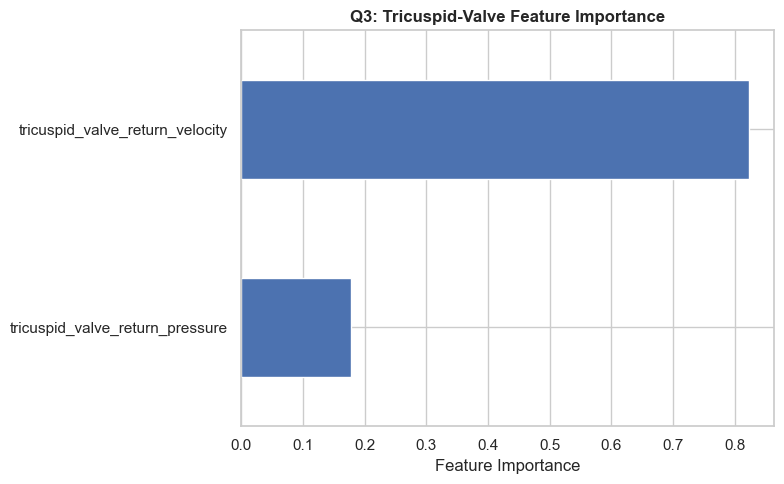

In [120]:
q3_importance = pd.Series(
    q3_rf.named_steps["model"].feature_importances_,
    index=q3_features
).sort_values(ascending=True)

q3_importance.plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title(
    "Q3: Tricuspid-Valve Feature Importance",
    fontweight="bold"
)
plt.xlabel("Feature Importance")

plt.tight_layout()
plt.show()

### Q3 – Assignment interpretation

> The analysis evaluated whether tricuspid-valve return velocity and return pressure could distinguish Right-sided heart failure from other heart-failure categories. The scatter plot shows the relationship between the two measurements, while the predictive models quantify their ability to classify the outcome.

# QUESTION 4

## Can the relationship between LVEF and left-ventricular diameter predict heart-failure type?

### Explanation

This question examines whether the combination of LVEF and left-ventricular end-diastolic diameter contains information that can be used to classify heart-failure type.

### Predictors

- `lvef`
- `left_ventricular_end_diastolic_diameter_lv`

### Target

`type_of_heart_failure`

### Cell 1 – Create Q4 dataset

In [121]:
q4_features = [
    "lvef",
    "left_ventricular_end_diastolic_diameter_lv"
]

q4_df = heart_df[
    q4_features + ["type_of_heart_failure"]
].copy()

q4_df.head()

,lvef,left_ventricular_end_diastolic_diameter_lv,type_of_heart_failure
0,NaN,NaN,Both
1,NaN,NaN,Both
2,NaN,40.0,Both
3,NaN,46.0,Both
4,NaN,NaN,Both


### Cell 2 – Check missing values

In [122]:
q4_df.isnull().sum()

lvef                                          1373
left_ventricular_end_diastolic_diameter_lv     697
type_of_heart_failure                            0
dtype: int64

### Cell 3 – Visualization: LVEF vs LV diameter

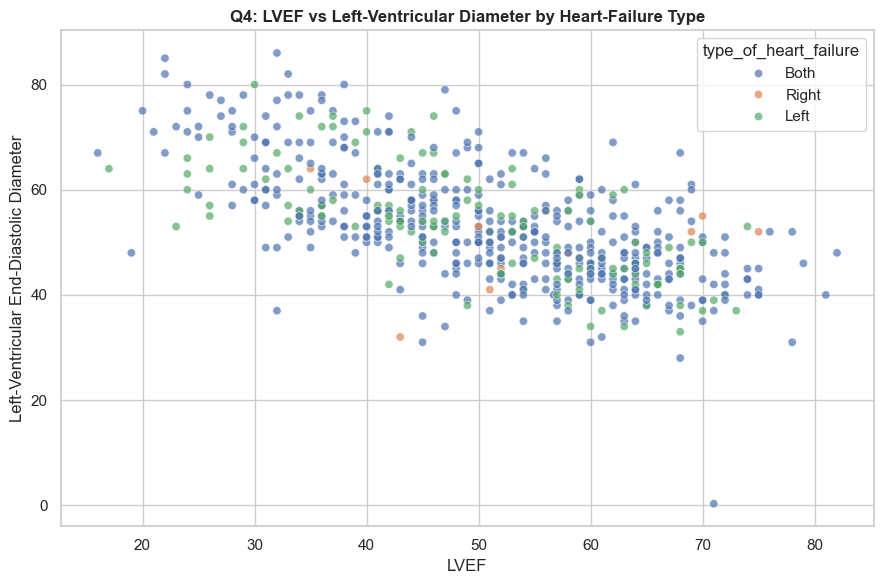

In [123]:
q4_plot = q4_df.dropna(
    subset=["type_of_heart_failure"]
).copy()

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=q4_plot,
    x="lvef",
    y="left_ventricular_end_diastolic_diameter_lv",
    hue="type_of_heart_failure",
    alpha=0.7
)

plt.title(
    "Q4: LVEF vs Left-Ventricular Diameter by Heart-Failure Type",
    fontweight="bold"
)
plt.xlabel("LVEF")
plt.ylabel("Left-Ventricular End-Diastolic Diameter")

plt.tight_layout()
plt.show()

### Cell 4 – Prepare X and y

In [124]:
q4_df = q4_df.dropna(
    subset=["type_of_heart_failure"]
)

X_q4 = q4_df[q4_features]
y_q4 = q4_df["type_of_heart_failure"].astype(str).str.strip()

print("X shape:", X_q4.shape)
print("y shape:", y_q4.shape)

X shape: (2008, 2)
y shape: (2008,)


### Cell 5 – Train/test split

In [125]:
X_train_q4, X_test_q4, y_train_q4, y_test_q4 = train_test_split(
    X_q4,
    y_q4,
    test_size=0.20,
    random_state=42,
    stratify=y_q4
)

print("Training records:", len(X_train_q4))
print("Testing records:", len(X_test_q4))

Training records: 1606
Testing records: 402


### Cell 6 – Logistic Regression

In [126]:
q4_logistic = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

q4_logistic.fit(X_train_q4, y_train_q4)
q4_logistic_pred = q4_logistic.predict(X_test_q4)

print("Q4 Logistic Regression completed!")

Q4 Logistic Regression completed!


### Cell 7 – Decision Tree

In [127]:
q4_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

q4_tree.fit(X_train_q4, y_train_q4)
q4_tree_pred = q4_tree.predict(X_test_q4)

print("Q4 Decision Tree completed!")

Q4 Decision Tree completed!


### Cell 8 – Random Forest

In [128]:
q4_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ))
])

q4_rf.fit(X_train_q4, y_train_q4)
q4_rf_pred = q4_rf.predict(X_test_q4)

print("Q4 Random Forest completed!")

Q4 Random Forest completed!


### Cell 9 – Evaluation

In [129]:
q4_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test_q4, q4_logistic_pred),
        accuracy_score(y_test_q4, q4_tree_pred),
        accuracy_score(y_test_q4, q4_rf_pred)
    ],
    "Precision": [
        precision_score(y_test_q4, q4_logistic_pred, average="weighted", zero_division=0),
        precision_score(y_test_q4, q4_tree_pred, average="weighted", zero_division=0),
        precision_score(y_test_q4, q4_rf_pred, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_q4, q4_logistic_pred, average="weighted", zero_division=0),
        recall_score(y_test_q4, q4_tree_pred, average="weighted", zero_division=0),
        recall_score(y_test_q4, q4_rf_pred, average="weighted", zero_division=0)
    ],
    "F1": [
        f1_score(y_test_q4, q4_logistic_pred, average="weighted", zero_division=0),
        f1_score(y_test_q4, q4_tree_pred, average="weighted", zero_division=0),
        f1_score(y_test_q4, q4_rf_pred, average="weighted", zero_division=0)
    ]
})

q4_results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.378109,0.627061,0.378109,0.459101
1,Decision Tree,0.554726,0.608704,0.554726,0.579015
2,Random Forest,0.552239,0.606254,0.552239,0.575791


### Cell 10 – Visualization: Model comparison

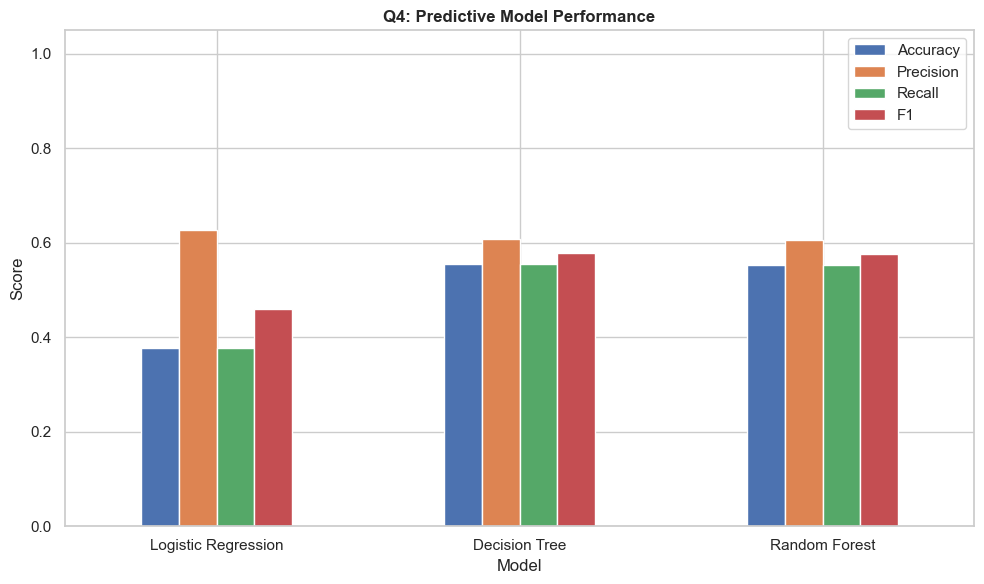

In [130]:
q4_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Q4: Predictive Model Performance",
    fontweight="bold"
)
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Cell 11 – Visualization: Confusion matrix

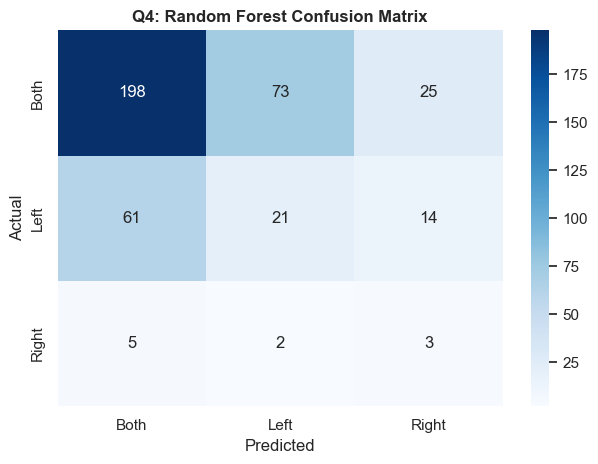

In [131]:
q4_cm = confusion_matrix(y_test_q4, q4_rf_pred)

sns.heatmap(
    q4_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y_test_q4.unique()),
    yticklabels=sorted(y_test_q4.unique())
)

plt.title(
    "Q4: Random Forest Confusion Matrix",
    fontweight="bold"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### Cell 12 – Visualization: Feature importance

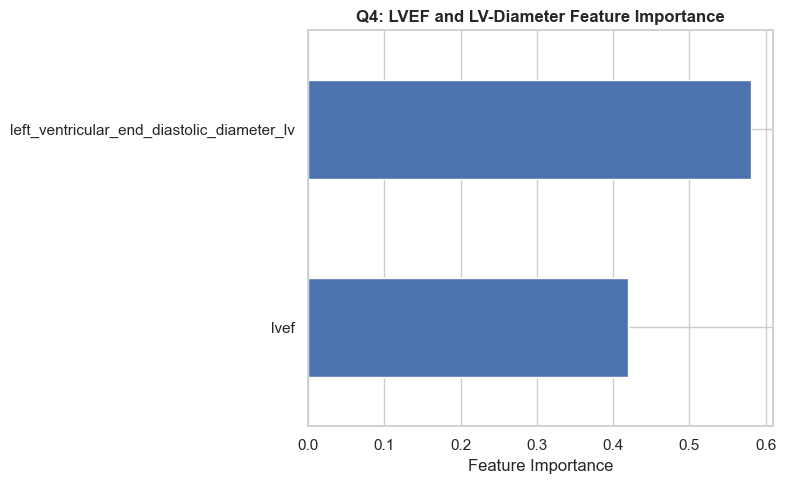

In [132]:
q4_importance = pd.Series(
    q4_rf.named_steps["model"].feature_importances_,
    index=q4_features
).sort_values(ascending=True)

q4_importance.plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title(
    "Q4: LVEF and LV-Diameter Feature Importance",
    fontweight="bold"
)
plt.xlabel("Feature Importance")

plt.tight_layout()
plt.show()

### Q4 – Assignment interpretation

> The analysis evaluated whether LVEF and left-ventricular end-diastolic diameter could be used together to classify heart-failure type. The scatter plot provides an exploratory view of the relationship, while the classification models quantify predictive performance.

# QUESTION 5

## Can NYHA classification and Killip grade together predict severe cardiac dysfunction?

### Explanation

The proposed predictors are:

- `nyha_cardiac_function_classification`
- `killip_grade`

However, the phrase **"severe cardiac dysfunction" is not itself a column in the cleaned dataset**. We need the assignment-approved rule for what counts as severe before building a valid target.

Therefore, this section first inspects the available variables instead of inventing a target.

### Cell 1 – Inspect Q5 candidate variables

In [133]:
q5_candidates = [
    "nyha_cardiac_function_classification",
    "killip_grade",
    "cci_score",
    "gcs",
    "outcome_during_hospitalization"
]

available_q5 = [
    col for col in q5_candidates
    if col in heart_df.columns
]

print("Available Q5 candidate variables:")
print(available_q5)

for col in available_q5:
    print("\n", col)
    print(heart_df[col].value_counts(dropna=False).head(15))

Available Q5 candidate variables:
['nyha_cardiac_function_classification', 'killip_grade', 'cci_score', 'gcs', 'outcome_during_hospitalization']

 nyha_cardiac_function_classification
nyha_cardiac_function_classification
3    1039
4     616
2     353
Name: count, dtype: int64

 killip_grade
killip_grade
2    1029
1     527
3     392
4      60
Name: count, dtype: int64

 cci_score
cci_score
1.0    770
2.0    699
3.0    368
4.0     94
0.0     56
5.0     15
NaN      5
6.0      1
Name: count, dtype: int64

 gcs
gcs
15    1951
11      19
3       13
10       7
14       7
7        4
12       3
13       2
6        1
4        1
Name: count, dtype: int64

 outcome_during_hospitalization
outcome_during_hospitalization
Alive                    1890
DischargeAgainstOrder     107
Dead                       11
Name: count, dtype: int64


### Q5 – What to do next

Do not create a severity target until the assignment/instructor specifies the definition.

For example, the final target could be based on an approved definition involving NYHA or Killip, but that definition must come from the project requirements rather than being invented in the analysis.

# QUESTION 6

## Can myocardial infarction, congestive heart failure, and peripheral vascular disease predict high clinical severity?

### Explanation

This question examines whether major cardiovascular comorbidities can be used as predictors of a defined high-severity outcome.

### Predictors

- `myocardial_infarction`
- `congestive_heart_failure`
- `peripheral_vascular_disease`

### Important

A target called **"high clinical severity"** is not directly available as a named column. The target definition must therefore be confirmed before predictive modeling.

### Cell 1 – Inspect Q6 predictor variables

In [134]:
q6_features = [
    "myocardial_infarction",
    "congestive_heart_failure",
    "peripheral_vascular_disease"
]

print("Q6 predictor availability:")

for col in q6_features:
    if col in heart_df.columns:
        print(
            f"\n{col}:",
            heart_df[col].value_counts(dropna=False).to_dict()
        )
    else:
        print(f"Missing column: {col}")

Q6 predictor availability:

myocardial_infarction: {0: 1865, 1: 143}

congestive_heart_failure: {1: 1872, 0: 136}

peripheral_vascular_disease: {0: 1907, 1: 101}


### Cell 2 – Visualization: Cardiovascular comorbidity counts

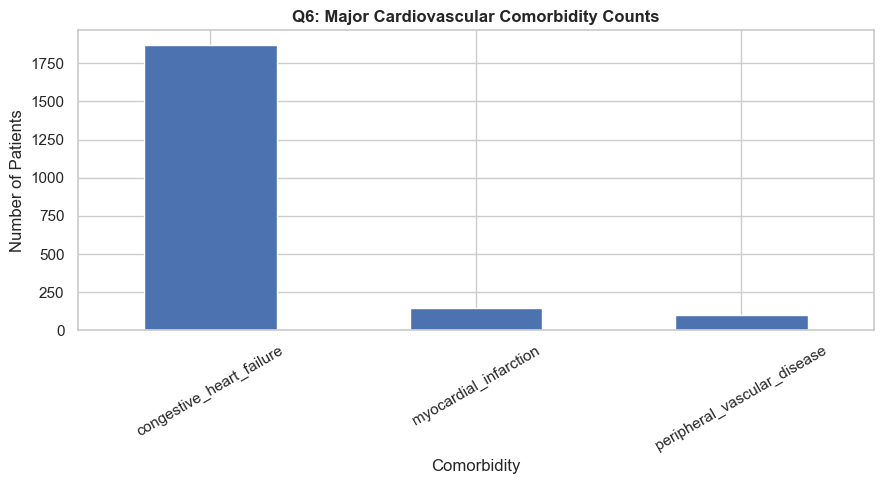

In [135]:
q6_counts = heart_df[q6_features].sum(
    numeric_only=True
).sort_values(ascending=False)

q6_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Q6: Major Cardiovascular Comorbidity Counts",
    fontweight="bold"
)
plt.xlabel("Comorbidity")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Q6 – Next step

Once the approved high-severity target is defined, the same modeling structure used in Q1–Q4 will be applied:

- X = the three comorbidities
- y = approved severity target
- train/test split
- Logistic Regression
- Decision Tree
- Random Forest
- Accuracy, Precision, Recall, F1
- Confusion matrix
- Feature importance

# QUESTION 7

## Can demographic characteristics combined with comorbidity patterns identify patients with severe cardiac presentation?

### Explanation

This question combines demographic characteristics with cardiovascular comorbidities.

Potential demographic variables must first be verified in the cleaned dataset.

Potential predictors include:

- demographic variables such as age/age group and gender, if available
- `myocardial_infarction`
- `congestive_heart_failure`
- `peripheral_vascular_disease`
- other validated comorbidities

The target **"severe cardiac presentation" must be explicitly defined before modeling**.

### Cell 1 – Inspect demographic and comorbidity columns

In [136]:
q7_candidates = [
    "gender",
    "age",
    "agecat",
    "weight",
    "height",
    "bmi",
    "myocardial_infarction",
    "congestive_heart_failure",
    "peripheral_vascular_disease",
    "cerebrovascular_disease",
    "diabetes",
    "chronic_obstructive_pulmonary_disease",
    "cci_score"
]

available_q7 = [
    col for col in q7_candidates
    if col in heart_df.columns
]

print("Available Q7 variables:")
for col in available_q7:
    print(" -", col)

Available Q7 variables:
 - gender
 - agecat
 - weight
 - height
 - bmi
 - myocardial_infarction
 - congestive_heart_failure
 - peripheral_vascular_disease
 - cerebrovascular_disease
 - diabetes
 - chronic_obstructive_pulmonary_disease
 - cci_score


### Cell 2 – Visualization: Available categorical demographic variable

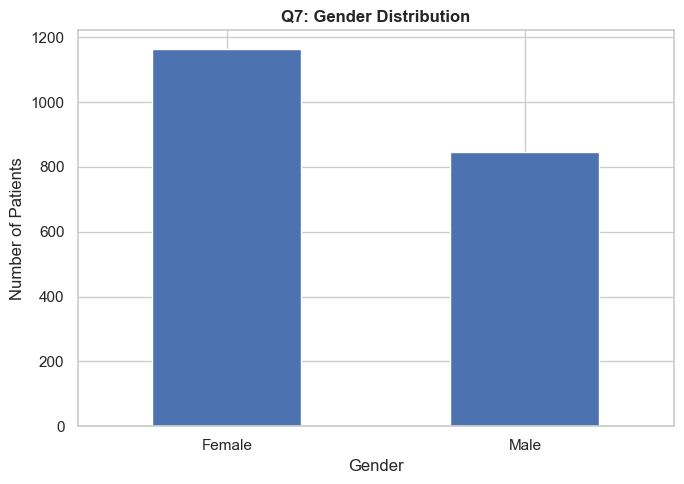

In [137]:
if "gender" in heart_df.columns:
    plt.figure(figsize=(7, 5))

    heart_df["gender"].value_counts().plot(
        kind="bar"
    )

    plt.title(
        "Q7: Gender Distribution",
        fontweight="bold"
    )
    plt.xlabel("Gender")
    plt.ylabel("Number of Patients")
    plt.xticks(rotation=0)

    plt.tight_layout()
    plt.show()
else:
    print("The gender column is not available in the cleaned dataset.")

### Cell 3 – Visualization: Comorbidity pattern

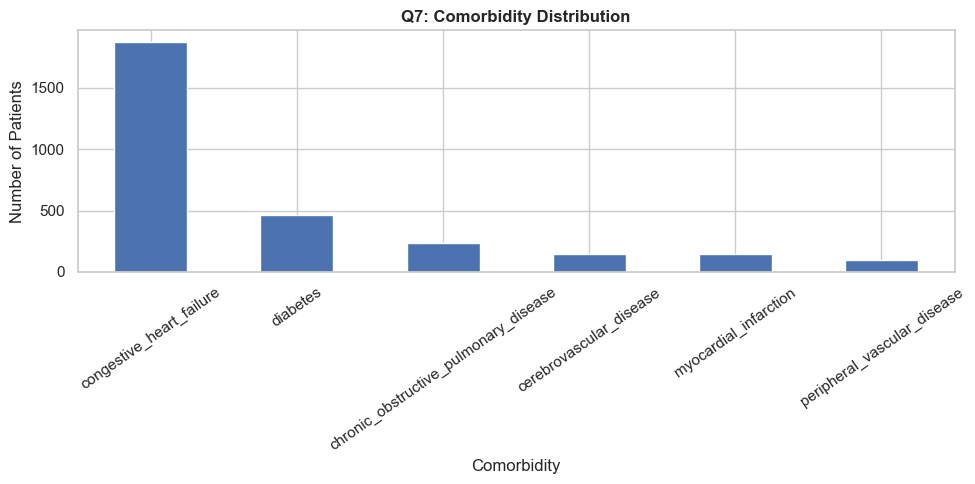

In [138]:
q7_comorbidities = [
    col for col in [
        "myocardial_infarction",
        "congestive_heart_failure",
        "peripheral_vascular_disease",
        "cerebrovascular_disease",
        "diabetes",
        "chronic_obstructive_pulmonary_disease"
    ]
    if col in heart_df.columns
]

if q7_comorbidities:
    heart_df[q7_comorbidities].sum().sort_values(
        ascending=False
    ).plot(
        kind="bar",
        figsize=(10, 5)
    )

    plt.title(
        "Q7: Comorbidity Distribution",
        fontweight="bold"
    )
    plt.xlabel("Comorbidity")
    plt.ylabel("Number of Patients")
    plt.xticks(rotation=35)

    plt.tight_layout()
    plt.show()
else:
    print("No Q7 comorbidity columns were found.")

### Q7 – Next step

After the assignment-approved definition of **severe cardiac presentation** is confirmed, this question will use:

1. validated demographic predictors
2. validated comorbidity predictors
3. the approved severity target
4. Logistic Regression
5. Decision Tree
6. Random Forest
7. Accuracy, Precision, Recall and F1
8. Confusion matrix
9. Feature importance

---

# FINAL NOTE

Q1–Q4 are complete predictive analyses.

Q5–Q7 are deliberately stopped at target validation because the cleaned data does not contain a column explicitly defining "severe cardiac dysfunction", "high clinical severity", or "severe cardiac presentation".

This prevents us from putting an unsupported medical definition into the assignment.

#### Question 8: Can we predict which heart-failure patients will be readmitted within 6 months using only admission-time data, and which clinical factors drive that risk the most?

ROC-AUC: 0.666 | Accuracy: 0.643


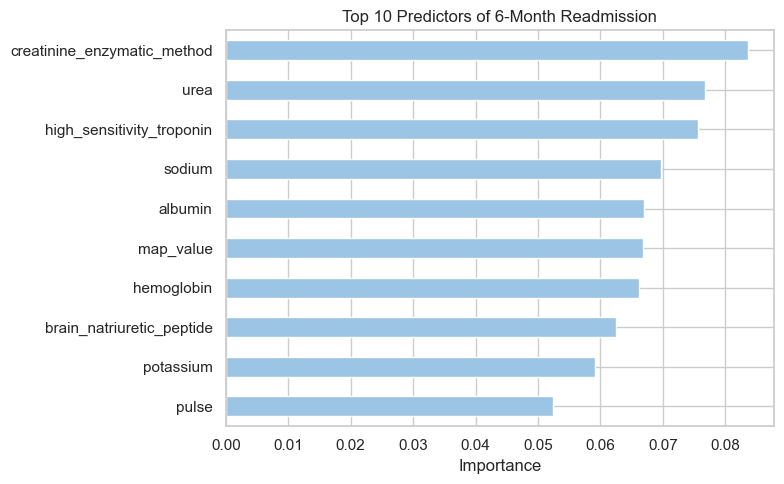

In [139]:
#  Predict 6-month readmission using admission-time information 


target = "re_admission_within_6_months"

candidate_features = [
    "gender", "agecat", "visit_times", "admission_ward", "admission_way",
    "killip_grade", "nyha_cardiac_function_classification", "cci_score", "lvef",
    "type_of_heart_failure", "diabetes", "myocardial_infarction",
    "congestive_heart_failure", "moderate_to_severe_chronic_kidney_disease",
    "map_value", "pulse", "respiration", "body_temperature",
    "brain_natriuretic_peptide", "high_sensitivity_troponin",
    "creatinine_enzymatic_method", "urea", "sodium", "potassium",
    "hemoglobin", "albumin"
]
features = [c for c in candidate_features if c in heart_df.columns]

data = heart_df[features + [target]].dropna(subset=[target])
X = data[features]
y = data[target].astype(int)

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

model = Pipeline([
    ("prep", preprocess),
    ("rf", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                  class_weight="balanced", random_state=42, n_jobs=-1))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
model.fit(X_train, y_train)

pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_test, proba):.3f} | Accuracy: {accuracy_score(y_test, pred):.3f}")

# Top 10 markers of readmission risk
names = model.named_steps["prep"].get_feature_names_out()
importance = (
    pd.Series(model.named_steps["rf"].feature_importances_, index=names)
    .sort_values(ascending=False).head(10)
)
importance.index = [n.split("__")[1] for n in importance.index]

ax = importance[::-1].plot(kind="barh", figsize=(8, 5), color="#9CC4E4")
plt.title("Top 10 Predictors of 6-Month Readmission")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

#### Kidney markers (creatinine, urea) and troponin are the strongest predictors of 6-month readmission (model ROC-AUC 0.67), consistent with our kidney-impairment and troponin findings. Patients with elevated creatinine, urea or troponin at admission should be flagged for early follow-up.

#### Question 9: Can routine non-kidney data (vitals, heart markers, blood counts, history) identify heart-failure patients likely to have impaired kidney function, so kidney tests and nephrology review can be prioritised early?

Patients: 2008 | Kidney impaired: 34.2%
Cross-validated ROC-AUC: 0.778


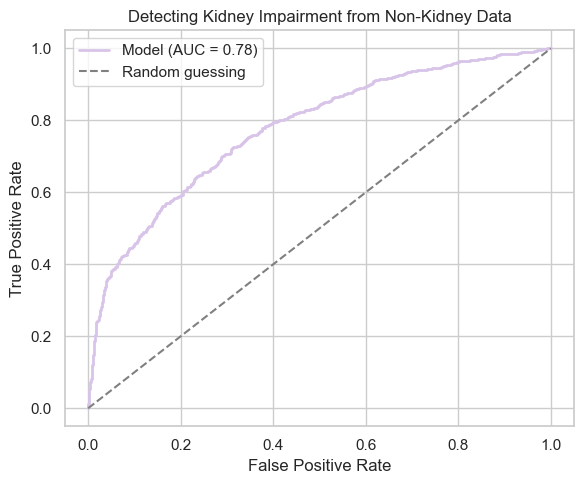

,% of flagged patients who are impaired,% of all impaired patients found
flagged,,
Top 10%,85.0,24.7
Top 20%,73.1,42.6
Top 30%,64.1,56.2


In [140]:
#  Predict kidney impairment from NON-kidney routine data


# Target: same definition as the kidney question
creat_cut = heart_df["creatinine_enzymatic_method"].quantile(0.75)
target = (
    (heart_df["creatinine_enzymatic_method"] >= creat_cut) |
    (heart_df["moderate_to_severe_chronic_kidney_disease"] == 1) |
    (heart_df["acute_renal_failure"] == 1)
).astype(int)
print(f"Patients: {len(target)} | Kidney impaired: {target.mean()*100:.1f}%")

# Inputs: NO kidney markers, NO cci_score
candidate_features = [
    "gender", "agecat", "visit_times", "type_of_heart_failure",
    "pulse", "respiration", "systolic_blood_pressure", "diastolic_blood_pressure", "map_value",
    "brain_natriuretic_peptide", "high_sensitivity_troponin", "sodium", "potassium",
    "hemoglobin", "albumin", "d_dimer", "diabetes", "myocardial_infarction",
    "congestive_heart_failure", "liver_disease"
]
features = [c for c in candidate_features if c in heart_df.columns]
X, y = heart_df[features], target

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

model = Pipeline([
    ("prep", ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
    ])),
    ("rf", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=15,
                                  class_weight="balanced", random_state=42, n_jobs=-1))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
risk = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
auc = roc_auc_score(y, risk)
print(f"Cross-validated ROC-AUC: {auc:.3f}")

# Triage table: flag the top 10/20/30% -> how many impaired patients are caught?
res = pd.DataFrame({"risk": risk, "actual": y.values}).sort_values("risk", ascending=False)
rows = []
for share in [0.10, 0.20, 0.30]:
    top = res.head(int(len(res) * share))
    rows.append({"flagged": f"Top {int(share*100)}%",
                 "impaired_rate_in_group": round(top["actual"].mean() * 100, 1),
                 "impaired_cases_caught": round(top["actual"].sum() / res["actual"].sum() * 100, 1)})
triage = pd.DataFrame(rows).set_index("flagged")

# ROC curve
fpr, tpr, _ = roc_curve(y, risk)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="#D8C4E8", linewidth=2, label=f"Model (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random guessing")
plt.title("Detecting Kidney Impairment from Non-Kidney Data")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

triage = pd.DataFrame(rows).set_index("flagged")
triage.columns = ["% of flagged patients who are impaired", "% of all impaired patients found"]
triage.loc[["Top 20%", "Top 30%"]]
triage

#### Using only routine tests (vitals, heart markers, blood counts, history) and no kidney markers, the model identifies kidney impairment with a ROC-AUC of 0.78, well above random guessing . it ranks patients from highest to lowest kidney risk, and the patients it ranks highest are far more likely to have kidney impairment than the average patient. This helps hospitals send kidney tests and specialist review to the highest-risk patients first. 

-----
# End of Predictive Analysis